# TriggerNet Level 1 — Notebook 01: LHC Jet Data & Physics Intuition

## Why This Step Matters at CERN
Inside the Large Hadron Collider (LHC), proton bunches collide **40 million times per second (40 MHz)**, generating roughly **100 TB/s** of raw detector data. CERN cannot possibly save all of that to disk.

Instead, a hardware filter called the **Level-1 (L1) Trigger** runs on ultra-fast chips (**FPGAs**) sitting right next to the detector. It has **a few microseconds** to inspect each collision and decide:
- **Keep it** (looks like rare, interesting physics), or
- **Discard it forever** (ordinary background collisions).

### What Is a "Jet" & What Are the 5 Classes?
When high-energy quarks or gluons fly out of a collision, the strong nuclear force turns them into narrow cones of dozens of particles called **jets**. Heavy unstable particles (`W`, `Z`, `top`) decay so fast that their decay products merge into one "fat" jet with distinct internal substructure:

| Class ID | Symbol | Particle | Physical Signature Inside the Jet |
| :--- | :---: | :--- | :--- |
| `0` | `g` | **Gluon** | Broad, messy single-core spray with **high particle multiplicity** |
| `1` | `q` | **Light Quark** | Narrower single-core spray with lower multiplicity (very hard to separate from `g`!) |
| `2` | `w` | **W Boson** | **2-prong** substructure, jet mass clustered around **~80 GeV** |
| `3` | `z` | **Z Boson** | **2-prong** substructure, jet mass clustered around **~91 GeV** (overlaps closely with `W`!) |
| `4` | `t` | **Top Quark** | **3-prong** substructure (`t → W + b → 3 quarks`), heavy jet mass around **~173 GeV** |

### What Are the 16 Summary Features?
In Level 1, we use the standard **`hls4ml_lhc_jets_hlf`** benchmark (830,000 simulated LHC jets, 16 high-level physics features):
- **`mass_mmdt`**: Groomed invariant mass of the jet (using *modified Mass Drop Tagger* grooming to strip away soft background noise / pileup). This is the single clearest separator for `W` (~80 GeV), `Z` (~91 GeV), and `t` (~173 GeV).
- **`multiplicity`**: Number of constituent particles inside the jet (gluons radiate more particles than quarks).
- **`zlogz`**: Energy-sharing entropy `Σ z_i log(z_i)` — measures whether energy is concentrated in 1 particle or spread across many.
- **`c1_b0/1/2_mmdt`, `c2_b1/2_mmdt`, `d2_b1/2_mmdt`, `d2_a1_b1/2_mmdt`, `m2_b1/2_mmdt`, `n2_b1/2_mmdt`**: **Energy Correlation Functions (ECFs)** and their ratios (`C2`, `D2`, `M2`, `N2`). Intuitively, these measure whether the jet has **1 core** (`q`/`g`), **2 prongs** (`W`/`Z`), or **3 prongs** (`t`) without even needing to guess sub-jet axes!

### Engineering Discipline in This Notebook
1. Inspect exact shapes, missing values, and class balance.
2. Visualize heavy tails & outliers — why **feature scaling is mandatory** both for gradient descent AND for fixed-point FPGA quantization later.
3. Verify zero data leakage: `StandardScaler` is fit **only** on the training split (60% train / 20% val / 20% test, stratified).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate project root cleanly whether run from notebooks/ or project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_PATH = PROJECT_ROOT / "data" / "hls4ml_lhc_jets_hlf.npz"
FIG_DIR = PROJECT_ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    import download_data
    download_data.main()

data = np.load(DATA_PATH, allow_pickle=True)
X_train_raw, X_val_raw, X_test_raw = data["X_train_raw"], data["X_val_raw"], data["X_test_raw"]
X_train, X_val, X_test = data["X_train"], data["X_val"], data["X_test"]
y_train, y_val, y_test = data["y_train"], data["y_val"], data["y_test"]
feature_names = [str(f) for f in data["feature_names"]]
class_names = [str(c) for c in data["class_names"]]

print(f"Total jets  : {len(y_train) + len(y_val) + len(y_test):,}")
print(f"Train split : {X_train.shape} (60%)")
print(f"Val split   : {X_val.shape} (20%)")
print(f"Test split  : {X_test.shape} (20%)")
print(f"Classes     : {class_names}")
print(f"Features    : {feature_names}")
print(f"Any NaN/Inf : train={not np.isfinite(X_train_raw).all()}, val={not np.isfinite(X_val_raw).all()}, test={not np.isfinite(X_test_raw).all()}")

Total jets  : 830,000
Train split : (498000, 16) (60%)
Val split   : (166000, 16) (20%)
Test split  : (166000, 16) (20%)
Classes     : ['g', 'q', 'w', 'z', 't']
Features    : ['zlogz', 'c1_b0_mmdt', 'c1_b1_mmdt', 'c1_b2_mmdt', 'c2_b1_mmdt', 'c2_b2_mmdt', 'd2_b1_mmdt', 'd2_b2_mmdt', 'd2_a1_b1_mmdt', 'd2_a1_b2_mmdt', 'm2_b1_mmdt', 'm2_b2_mmdt', 'n2_b1_mmdt', 'n2_b2_mmdt', 'mass_mmdt', 'multiplicity']
Any NaN/Inf : train=False, val=False, test=False


## 1. Class Balance Check
First rule of ML on physics datasets: **never train before checking class balance**. If one class is 10× rarer, plain accuracy becomes meaningless and loss weighting may be needed. Let's inspect all three stratified splits.

In [2]:
balance_rows = []
for idx, cname in enumerate(class_names):
    tr_n = int((y_train == idx).sum())
    va_n = int((y_val == idx).sum())
    te_n = int((y_test == idx).sum())
    tot = tr_n + va_n + te_n
    balance_rows.append({
        "Class": cname,
        "Train": tr_n,
        "Val": va_n,
        "Test": te_n,
        "Total": tot,
        "Share (%)": round(100.0 * tot / (len(y_train) + len(y_val) + len(y_test)), 2),
    })

balance_df = pd.DataFrame(balance_rows)
print(balance_df.to_string(index=False))

Class  Train   Val  Test  Total  Share (%)
    g 100275 33425 33425 167125      20.14
    q  96640 32213 32213 161066      19.41
    w 100250 33416 33417 167083      20.13
    z 100125 33375 33375 166875      20.11
    t 100710 33571 33570 167851      20.22


## 2. Feature Scales, Skewness & Heavy Tails (Why Normalization Is Crucial)
Notice two huge engineering facts in the statistics table below:
1. **Wildly different scales:** `mass_mmdt` ranges up to hundreds of GeV, `multiplicity` is in the dozens, while Energy Correlation Functions (`c1_b2_mmdt`, `m2_b2_mmdt`) live around `0.001–0.5`. Without `StandardScaler`, gradients explode on large-scale features and barely move on small-scale features.
2. **Hardware Quantization Impact:** On an FPGA (`ap_fixed<W, I>`), every input feature shares a tight fixed-point dynamic range (e.g. `[-8, +8)`). Standardizing features to mean `0` and std `1` maps ~99% of inputs cleanly into `[-4, +4]`, preventing fixed-point overflow!

In [3]:
stats_rows = []
for i, fname in enumerate(feature_names):
    col = X_train_raw[:, i]
    col_s = X_train[:, i]
    stats_rows.append({
        "Feature": fname,
        "Raw Min": np.min(col),
        "Raw Median": np.median(col),
        "Raw P99": np.percentile(col, 99),
        "Raw Max": np.max(col),
        "Raw Mean": np.mean(col),
        "Raw Std": np.std(col),
        "Scaled |x|>5 (%)": 100.0 * np.mean(np.abs(col_s) > 5.0),
    })

stats_df = pd.DataFrame(stats_rows)
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)
print(stats_df.to_string(index=False, float_format=lambda v: f"{v:8.4f}"))

      Feature  Raw Min  Raw Median  Raw P99  Raw Max  Raw Mean  Raw Std  Scaled |x|>5 (%)
        zlogz  -4.7595     -2.9101  -1.3854  -0.4390   -2.8658   0.5805            0.0000
   c1_b0_mmdt   0.0911      0.4522   0.4862   0.4938    0.4334   0.0555            0.2717
   c1_b1_mmdt   0.0001      0.0379   0.1087   0.1652    0.0378   0.0292            0.0000
   c1_b2_mmdt   0.0000      0.0059   0.0363   0.0704    0.0080   0.0094            0.0225
   c2_b1_mmdt   0.0000      0.0368   0.1517   0.2190    0.0456   0.0387            0.0000
   c2_b2_mmdt   0.0000      0.0025   0.0535   0.1079    0.0076   0.0122            0.2102
   d2_b1_mmdt   0.0059      1.2775   2.5545   3.9681    1.2949   0.4580            0.0018
   d2_b2_mmdt   0.0002      0.9825   3.2502   6.0282    1.0831   0.7301            0.0229
d2_a1_b1_mmdt   0.0059      1.2775   2.5545   3.9681    1.2949   0.4580            0.0018
d2_a1_b2_mmdt   0.0002      0.1931   0.3337   0.3666    0.1904   0.0754            0.0000
   m2_b1_m

## 3. Physics Sanity Plot: Jet Mass Spectrum (`mass_mmdt`)
Before training any neural network, a particle physicist checks whether the data actually obeys physics.
Let's plot `mass_mmdt` separated by true particle class. You should immediately see:
- **W Boson (`w`)** peaking sharply around **~80 GeV**
- **Z Boson (`z`)** peaking sharply around **~91 GeV**
- **Top Quark (`t`)** peaking around **~173 GeV** (with a secondary W peak when one top decay product escapes the jet cone!)
- **Gluon (`g`)** and **Light Quark (`q`)** falling smoothly at lower masses.

Saved /home/darkgem276/Rafay/.cern/projects/triggernet/figures/01_class_balance_and_mass.png


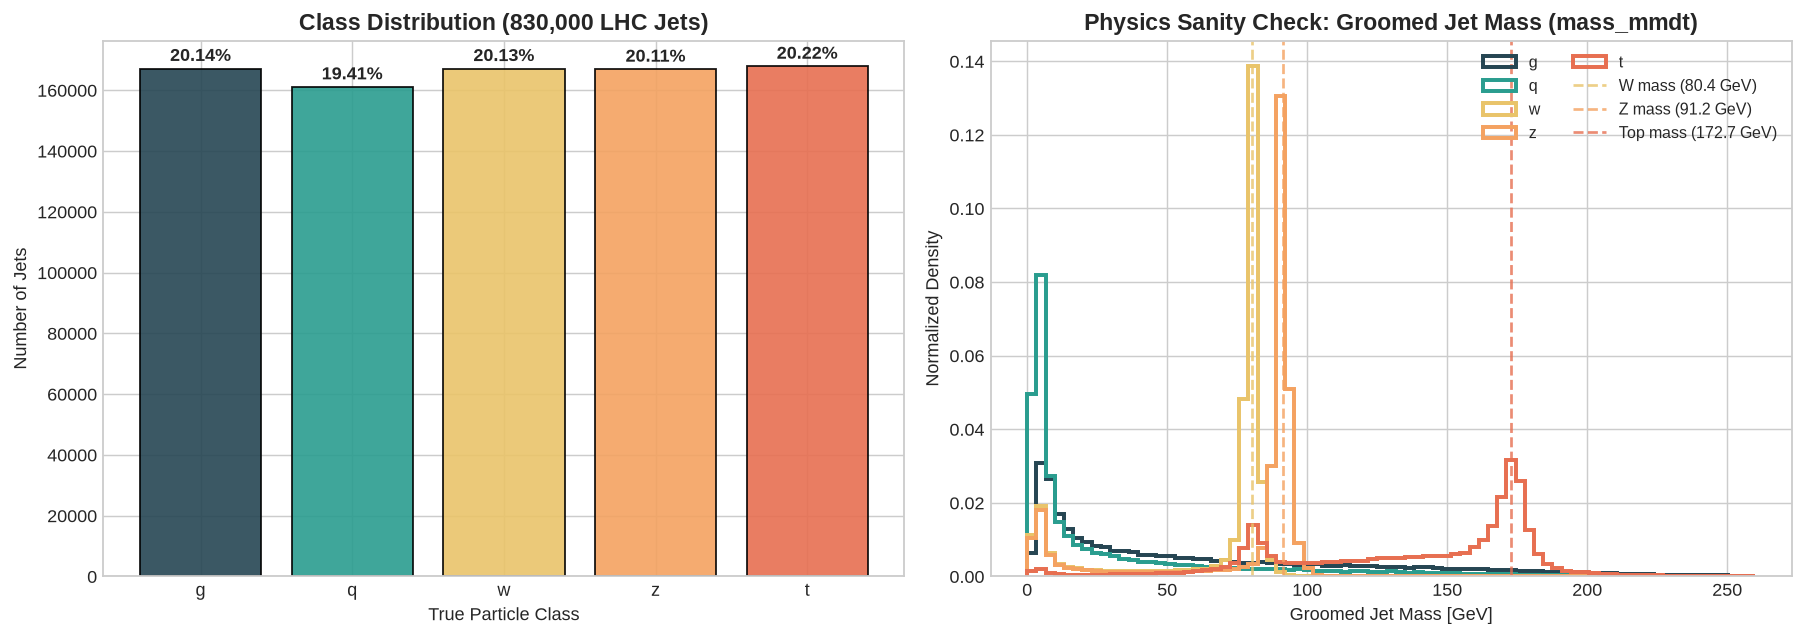

In [4]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Class balance across splits
colors = ["#264653", "#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"]
axes[0].bar(balance_df["Class"], balance_df["Total"], color=colors, edgecolor="black", alpha=0.9)
axes[0].set_title("Class Distribution (830,000 LHC Jets)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("True Particle Class")
axes[0].set_ylabel("Number of Jets")
for idx, row in balance_df.iterrows():
    axes[0].text(idx, row["Total"] + 2500, f"{row['Share (%)']}%", ha="center", fontweight="bold")

# Right: Groomed jet mass by particle class
mass_idx = feature_names.index("mass_mmdt")
bins = np.linspace(0, 260, 80)
for idx, cname in enumerate(class_names):
    vals = X_train_raw[y_train == idx, mass_idx]
    axes[1].hist(vals, bins=bins, density=True, histtype="step", linewidth=2.2, color=colors[idx], label=f"{cname}")

axes[1].axvline(80.4, color="#e9c46a", linestyle="--", alpha=0.8, label="W mass (80.4 GeV)")
axes[1].axvline(91.2, color="#f4a261", linestyle="--", alpha=0.8, label="Z mass (91.2 GeV)")
axes[1].axvline(172.7, color="#e76f51", linestyle="--", alpha=0.8, label="Top mass (172.7 GeV)")
axes[1].set_title("Physics Sanity Check: Groomed Jet Mass (mass_mmdt)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Groomed Jet Mass [GeV]")
axes[1].set_ylabel("Normalized Density")
axes[1].legend(fontsize=9, ncol=2)

plt.tight_layout()
out_path = FIG_DIR / "01_class_balance_and_mass.png"
plt.savefig(out_path, dpi=150)
plt.show()
print(f"Saved {out_path}")

## 4. All 16 Features (Standardized) & Correlation Matrix
Let's inspect all 16 scaled feature distributions (clipped at `[-5, 5]` for visual clarity) AND their pairwise Pearson correlation matrix.
Watch the correlation heatmap closely: many Energy Correlation Functions (`c1`, `c2`, `d2`, `m2`, `n2`) are strongly correlated with each other. That redundancy is a **hint** for Notebook 03: when we prune 50%–75% of weights later, the network will survive surprisingly well because redundant input pathways can be safely pruned!

Saved /home/darkgem276/Rafay/.cern/projects/triggernet/figures/01_feature_distributions.png


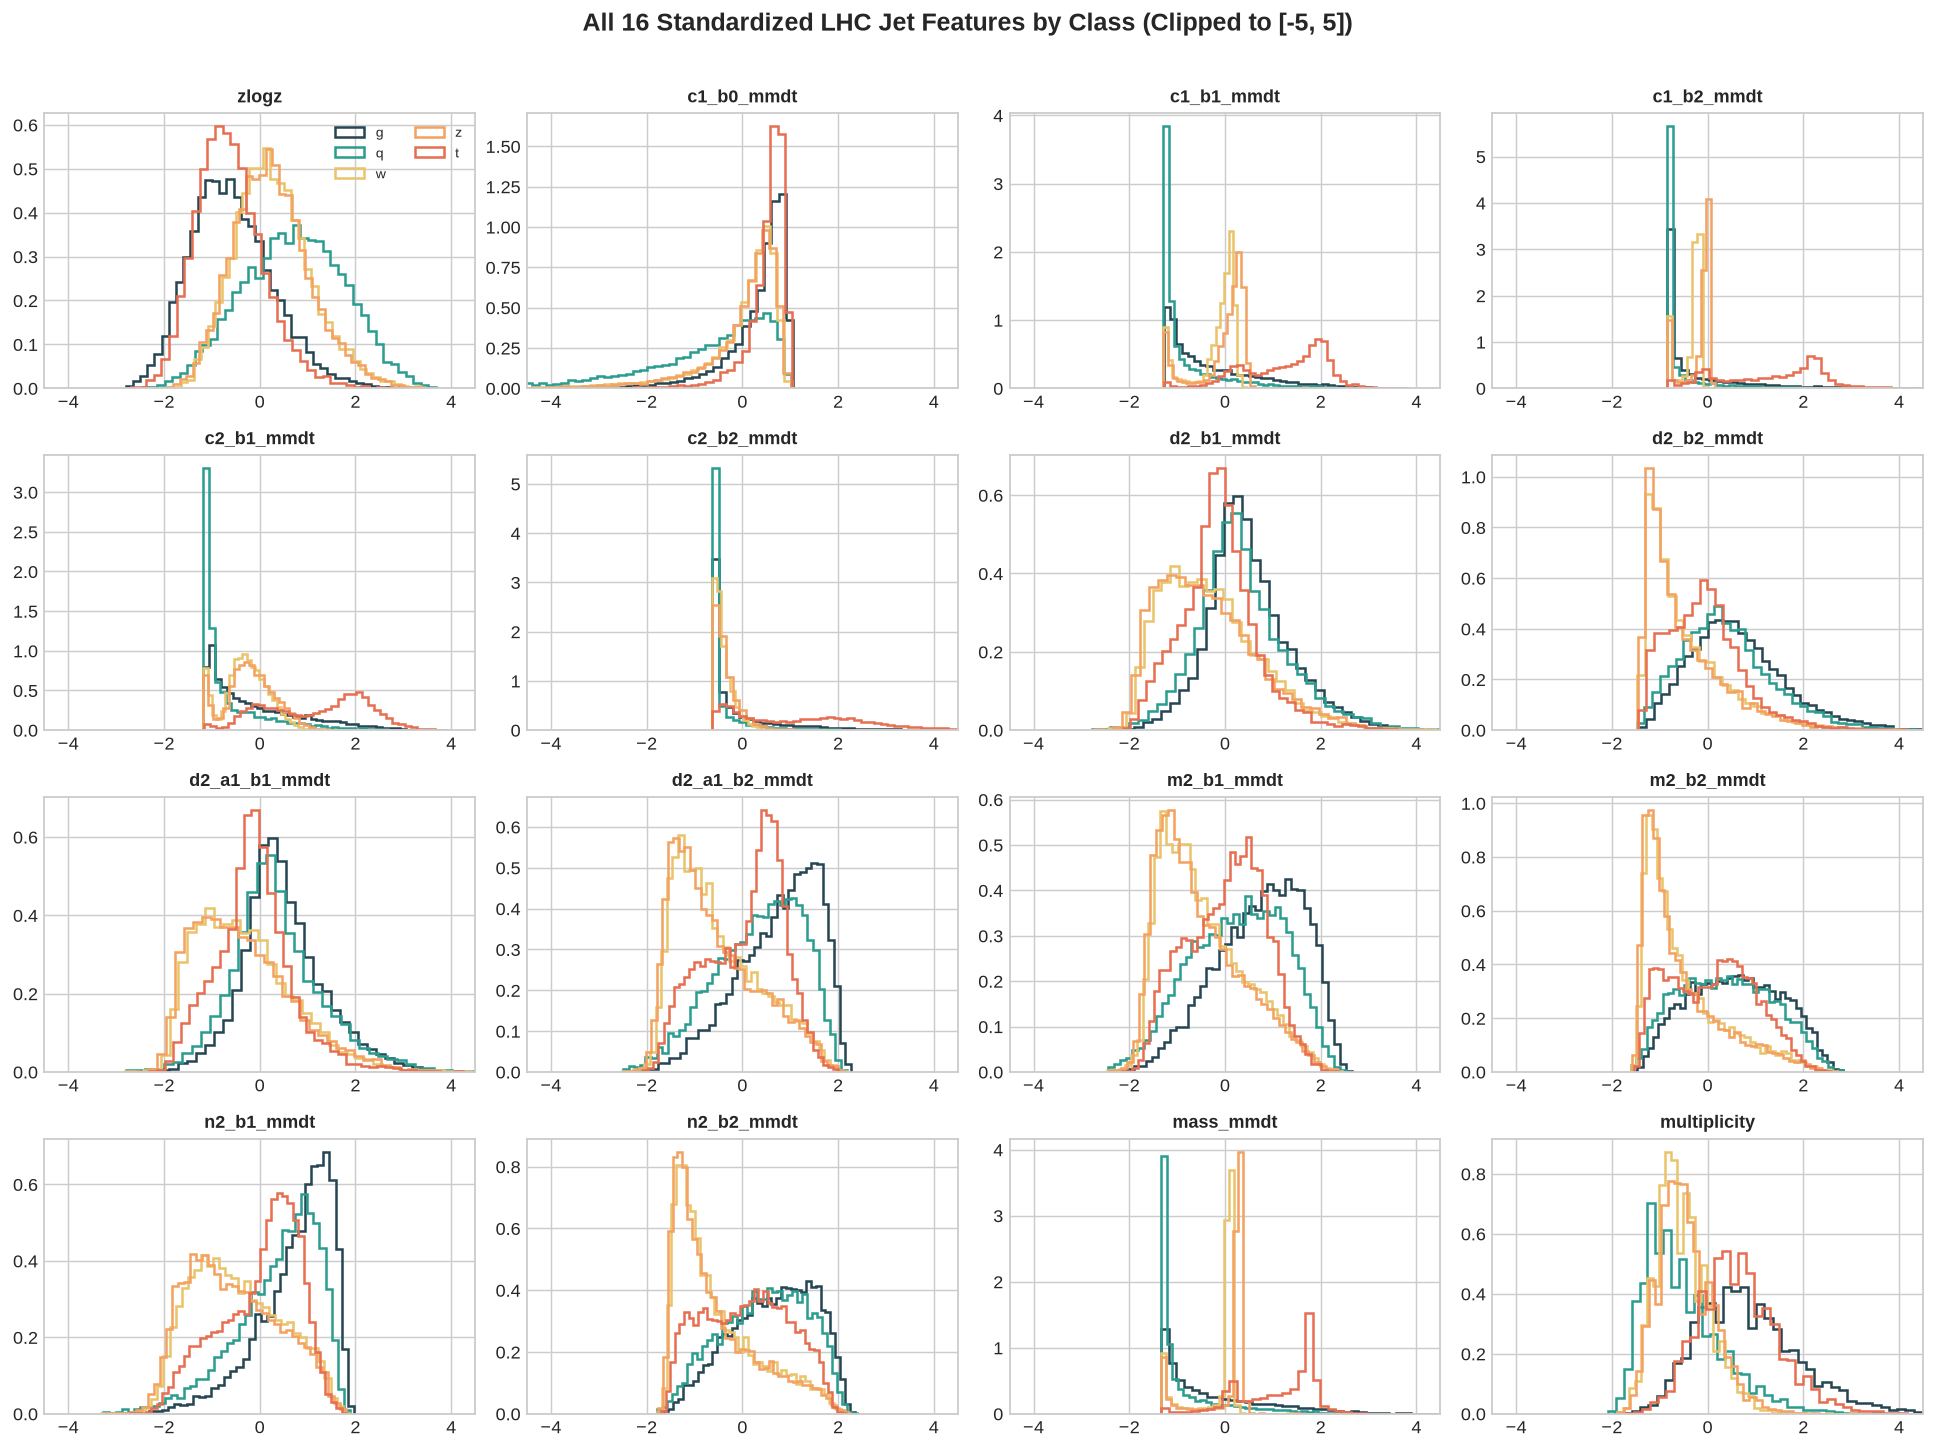

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_train), size=50_000, replace=False)
X_vis = X_train[sample_idx]
y_vis = y_train[sample_idx]

for i, ax in enumerate(axes.flat):
    for c_idx, cname in enumerate(class_names):
        vals = np.clip(X_vis[y_vis == c_idx, i], -5, 5)
        ax.hist(vals, bins=40, density=True, histtype="step", linewidth=1.4, color=colors[c_idx], label=cname)
    ax.set_title(feature_names[i], fontsize=10, fontweight="bold")
    ax.set_xlim(-4.5, 4.5)
    if i == 0:
        ax.legend(fontsize=8, ncol=2)

fig.suptitle("All 16 Standardized LHC Jet Features by Class (Clipped to [-5, 5])", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
out_path = FIG_DIR / "01_feature_distributions.png"
plt.savefig(out_path, dpi=140, bbox_inches="tight")
plt.show()
print(f"Saved {out_path}")

Saved /home/darkgem276/Rafay/.cern/projects/triggernet/figures/01_feature_correlation.png


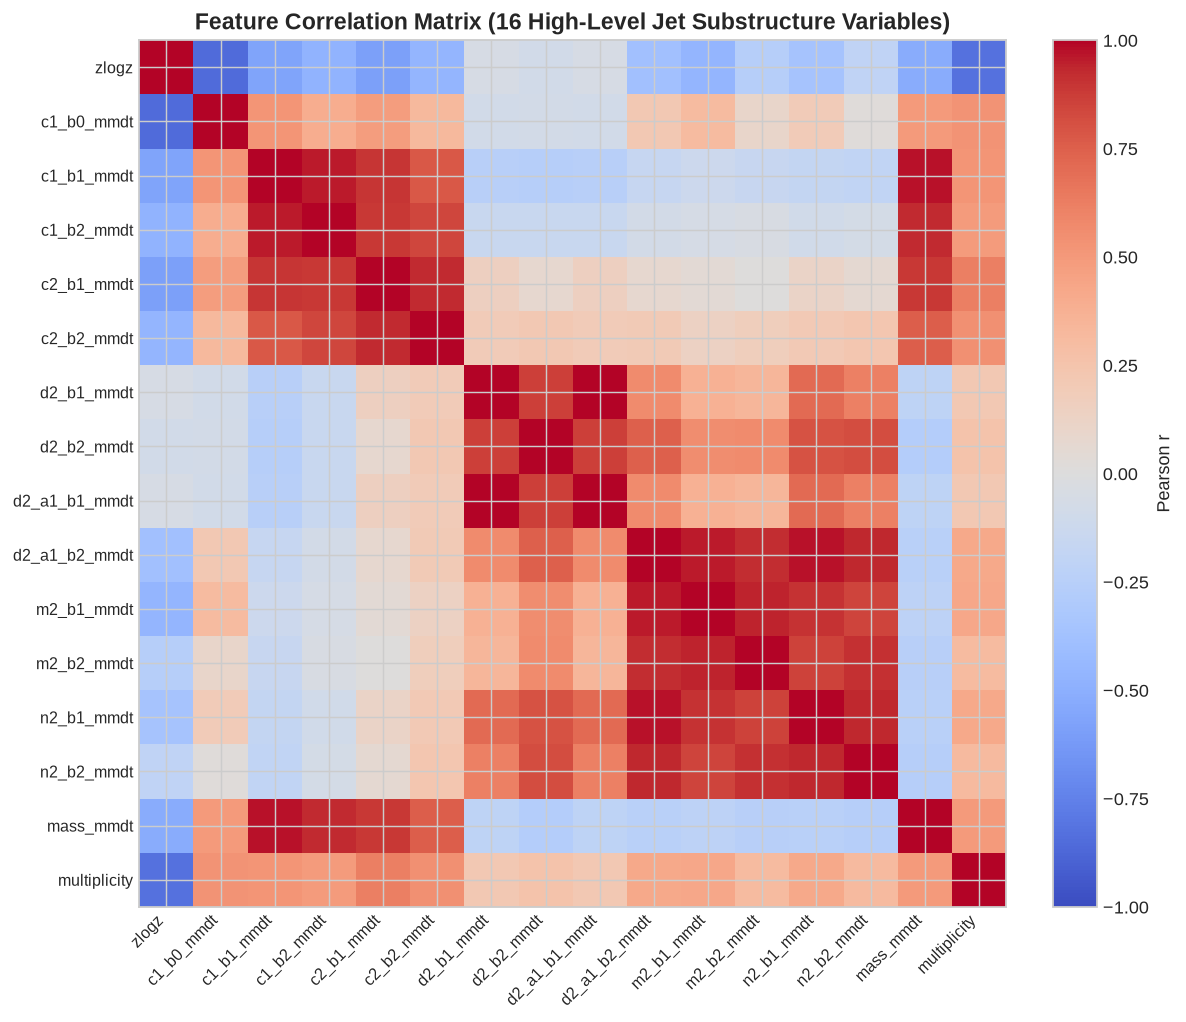

In [6]:
corr = np.corrcoef(X_train[sample_idx], rowvar=False)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_names)))
ax.set_yticks(range(len(feature_names)))
ax.set_xticklabels(feature_names, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(feature_names, fontsize=9)
ax.set_title("Feature Correlation Matrix (16 High-Level Jet Substructure Variables)", fontsize=13, fontweight="bold")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson r")
plt.tight_layout()
out_path = FIG_DIR / "01_feature_correlation.png"
plt.savefig(out_path, dpi=150)
plt.show()
print(f"Saved {out_path}")

## Step 1 Takeaways (Interview Checkpoints)
1. **Is the dataset balanced?** Yes — all 5 classes (`g, q, w, z, t`) sit right around ~20% each (~166k jets per class across 830k total).
2. **Why fit `StandardScaler` ONLY on `X_train`?** Fitting mean/std on validation or test data leaks test distribution statistics into training. In real deployment, the FPGA applies fixed pre-computed scaling constants derived strictly from training/simulation data.
3. **Which classes will be hardest for our MLP?** Physically, `g` vs `q` (both single-prong QCD jets) and `w` vs `z` (80.4 vs 91.2 GeV 2-prong bosons, close to detector mass resolution) will dominate our confusion matrix in Notebook 02!

**Next up → Open `02_float_baseline.ipynb` to train our PyTorch Float32 baseline MLP and measure CERN trigger ROC/Background Rejection metrics.**